# EDA: ETL9B handwritten characters (`data/etl9b`)

Source: the `repacked_etl9b` mirror of AIST ETL9B (binarised sibling of ETL9G): `metadata.tsv`
with one row per sample and `images.bin` with concatenated 1-bit PNGs, 64×63 px.
Population: every row in `metadata.tsv`. Questions:

1. How many samples, classes, and writer sheets are there, and is the set balanced per class?
2. What is the extra block at the end of file 5?
3. What do the images look like (ink coverage, bounding box)?
4. How many ETL9B classes also exist in KanjiVG (`data/kanji`)?

In [1]:
from pathlib import Path
import io
import unicodedata

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

ETL9B_DIR = Path("data/etl9b/repacked_etl9b")
KANJIVG_DIR = Path("data/kanji")

In [2]:
SERIES_BLUE = "#2a78d6"
TEXT_SECONDARY = "#52514e"
GRID_GRAY = "#e6e5e1"

plt.rcParams.update({
    "figure.dpi": 100,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": GRID_GRAY,
    "axes.labelcolor": TEXT_SECONDARY,
    "xtick.color": TEXT_SECONDARY,
    "ytick.color": TEXT_SECONDARY,
    "axes.grid": True,
    "axes.grid.axis": "y",
    "grid.color": GRID_GRAY,
    "axes.axisbelow": True,
    "font.family": ["Noto Sans CJK JP", "DejaVu Sans"],
})

## 1. Files and records

In [3]:
metadata = pd.read_csv(ETL9B_DIR / "metadata.tsv", sep="\t")
images_bin_size = (ETL9B_DIR / "images.bin").stat().st_size
print("metadata rows:", len(metadata), " images.bin bytes:", images_bin_size)
metadata.head()

metadata rows: 610236  images.bin bytes: 192723558


,char,dataset_source,width,height,seek_start,seek_end,sheet_number,jis_reading
0,あ,ETL9B/ETL9B_1,64,63,0,266,1,A.HI
1,い,ETL9B/ETL9B_1,64,63,266,426,1,I.HI
2,う,ETL9B/ETL9B_1,64,63,426,638,1,U.HI
3,え,ETL9B/ETL9B_1,64,63,638,872,2,E.HI
4,お,ETL9B/ETL9B_1,64,63,872,1106,2,O.HI


In [4]:
record_lengths = metadata["seek_end"] - metadata["seek_start"]
contiguous = (metadata["seek_start"].values[1:] == metadata["seek_end"].values[:-1]).all()
print("records contiguous:", contiguous, " last seek_end == file size:",
      metadata["seek_end"].iloc[-1] == images_bin_size)
print("image sizes:", metadata[["width", "height"]].drop_duplicates().values.tolist())
record_lengths.describe().round(1)

records contiguous: True  last seek_end == file size: True
image sizes: [[64, 63]]


count    610236.0
mean        315.8
std          37.2
min         106.0
25%         295.0
50%         321.0
75%         342.0
max         437.0
dtype: float64

In [5]:
metadata["source_file"] = metadata["dataset_source"].str.split("/").str[-1]
metadata.groupby("source_file").agg(rows=("char", "size"),
                                    sheet_min=("sheet_number", "min"),
                                    sheet_max=("sheet_number", "max"))

,rows,sheet_min,sheet_max
source_file,,,
ETL9B_1,121440,1,800
ETL9B_2,121440,801,1600
ETL9B_3,121440,1601,2400
ETL9B_4,121440,2401,3200
ETL9B_5,124476,1,4000


## 2. Extra block in file 5

In [6]:
ROWS_PER_FILE = 121_440
file5_rows = metadata[metadata["source_file"] == "ETL9B_5"]
extra_block = file5_rows.iloc[ROWS_PER_FILE:]
print("rows in file 5 beyond the regular", ROWS_PER_FILE, ":", len(extra_block))
print("distinct characters in extra block:", extra_block["char"].nunique(),
      " sheet range:", extra_block["sheet_number"].min(), "-", extra_block["sheet_number"].max())

rows in file 5 beyond the regular 121440 : 3036
distinct characters in extra block: 3036  sheet range: 1 - 20


In [7]:
def read_png_bytes(images_file, row):
    images_file.seek(int(row["seek_start"]))
    return images_file.read(int(row["seek_end"] - row["seek_start"]))


def decode_png(png_bytes):
    return np.array(Image.open(io.BytesIO(png_bytes)), dtype=bool)


regular_rows = metadata.drop(extra_block.index)
regular_lookup = regular_rows.set_index(["char", "sheet_number"])
with open(ETL9B_DIR / "images.bin", "rb") as images_file:
    identical = []
    for _, extra_row in extra_block.iterrows():
        regular_row = regular_lookup.loc[(extra_row["char"], extra_row["sheet_number"])]
        identical.append(read_png_bytes(images_file, extra_row) == read_png_bytes(images_file, regular_row))
extra_block_duplicates = int(np.sum(identical))
print("extra-block records byte-identical to the regular record with the same (char, sheet):",
      extra_block_duplicates, "of", len(extra_block))

extra-block records byte-identical to the regular record with the same (char, sheet): 0 of 3036


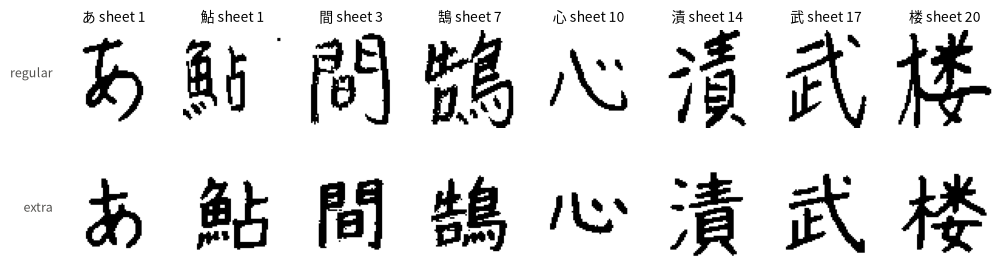

In [8]:
comparison_characters = extra_block["char"].iloc[[0, 100, 500, 1000, 1500, 2000, 2500, 3000]].tolist()
figure, axes = plt.subplots(2, len(comparison_characters), figsize=(12, 3.2))
with open(ETL9B_DIR / "images.bin", "rb") as images_file:
    for column, character in enumerate(comparison_characters):
        extra_row = extra_block[extra_block["char"] == character].iloc[0]
        regular_row = regular_lookup.loc[(character, extra_row["sheet_number"])]
        axes[0, column].imshow(decode_png(read_png_bytes(images_file, regular_row)), cmap="gray_r")
        axes[1, column].imshow(decode_png(read_png_bytes(images_file, extra_row)), cmap="gray_r")
        axes[0, column].set_title(f"{character} sheet {extra_row['sheet_number']}", fontsize=10)
for axis in axes.flat:
    axis.axis("off")
axes[0, 0].text(-8, 30, "regular", ha="right", fontsize=9, color=TEXT_SECONDARY)
axes[1, 0].text(-8, 30, "extra", ha="right", fontsize=9, color=TEXT_SECONDARY)
plt.show()

⚠️ The extra block is dropped from the sample population: its records are not duplicates, but
they sit outside the documented 200 samples per class and their sheet numbers (1–20) reuse
existing writer ids. Hypothesis: they are the ETL9B "mean pattern" records appended to file 5.

In [9]:
samples = regular_rows.reset_index(drop=True)
print("rows before:", len(metadata), " after dropping extra block:", len(samples))

rows before: 610236  after dropping extra block: 607200


## 3. Characters and classes

In [10]:
def character_class(character):
    name = unicodedata.name(character, "?")
    first_word = name.split()[0]
    if first_word == "CJK":
        return "CJK ideograph"
    if first_word in {"HIRAGANA", "KATAKANA"}:
        return "kana"
    return "other"


samples["character_class"] = samples["char"].map(character_class)
class_table = samples.drop_duplicates("char")["character_class"].value_counts()
print("distinct characters:", samples["char"].nunique())
pd.DataFrame({"classes": class_table, "share": (class_table / class_table.sum()).round(4)})

distinct characters: 3036


,classes,share
character_class,,
CJK ideograph,2965,0.9766
kana,71,0.0234


In [11]:
samples_per_class = samples.groupby("char").size()
samples_per_class.value_counts().rename_axis("samples per class").rename("classes")

samples per class
200    3036
Name: classes, dtype: int64

In [12]:
unique_characters = samples.drop_duplicates("char")
print("first 40 characters in file order:", "".join(unique_characters["char"].head(40)))
print("last 40 characters in file order: ", "".join(unique_characters["char"].tail(40)))

first 40 characters in file order: あいうえおかがきぎくぐけげこごさざしじすずせぜそぞただちぢつづてでとどなにぬねの
last 40 characters in file order:  婁廊弄朗楼榔浪漏牢狼篭老聾蝋郎六麓禄肋録論倭和話歪賄脇惑枠鷲亙亘鰐詫藁蕨椀湾碗腕


## 4. Writer sheets

In [13]:
rows_per_sheet = samples.groupby("sheet_number").size()
print("distinct sheets:", len(rows_per_sheet))
rows_per_sheet.describe().round(2)

distinct sheets: 4000


count    4000.0
mean      151.8
std         0.4
min       151.0
25%       152.0
50%       152.0
75%       152.0
max       152.0
dtype: float64

In [14]:
sheets_per_character = samples.groupby("char")["sheet_number"].nunique()
print("sheets per character: min", sheets_per_character.min(), " max", sheets_per_character.max())
print("characters appearing twice on one sheet:",
      (samples.groupby(["char", "sheet_number"]).size() > 1).sum())

sheets per character: min 200  max 200


characters appearing twice on one sheet: 0


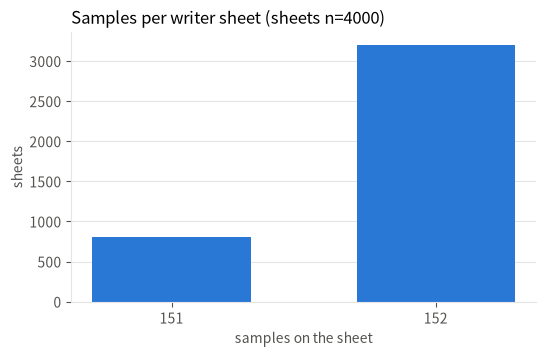

In [15]:
rows_per_sheet_distribution = rows_per_sheet.value_counts().sort_index()

figure, axis = plt.subplots(figsize=(6, 3.5))
axis.bar(rows_per_sheet_distribution.index.astype(str), rows_per_sheet_distribution.values,
         color=SERIES_BLUE, width=0.6)
axis.set_xlabel("samples on the sheet")
axis.set_ylabel("sheets")
axis.set_title(f"Samples per writer sheet (sheets n={len(rows_per_sheet)})", loc="left")
plt.show()

## 5. Images

⚠️ Image statistics use a seeded random sample of 12,000 records, not all 607k. A fixed stride
was tried first and covered only half the classes because the file order cycles over classes.

In [16]:
IMAGE_SAMPLE_SIZE = 12_000
image_sample_rows = samples.sample(IMAGE_SAMPLE_SIZE, random_state=0).reset_index(drop=True)

with open(ETL9B_DIR / "images.bin", "rb") as images_file:
    sample_images = np.stack([
        decode_png(read_png_bytes(images_file, row)) for _, row in image_sample_rows.iterrows()
    ])
print("sample images:", sample_images.shape, " dtype:", sample_images.dtype,
      " classes covered:", image_sample_rows["char"].nunique())

sample images: (12000, 63, 64)  dtype: bool  classes covered: 2978


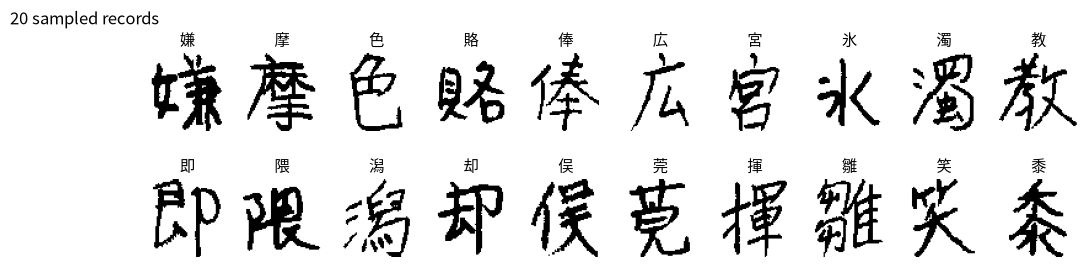

In [17]:
figure, axes = plt.subplots(2, 10, figsize=(12, 3))
for axis, index in zip(axes.flat, range(20)):
    axis.imshow(sample_images[index], cmap="gray_r")
    axis.set_title(image_sample_rows.loc[index, "char"], fontsize=11)
    axis.axis("off")
plt.suptitle("20 sampled records", x=0.01, ha="left")
plt.show()

⚠️ Ink = pixel value `True` in the 1-bit PNG. The first grid above shows this renders strokes
dark on `gray_r`; if strokes appeared inverted, the polarity assumption would be wrong.

In [18]:
ink_share_per_image = sample_images.mean(axis=(1, 2))
print("ink share per image:")
pd.Series(ink_share_per_image).describe().round(4)

ink share per image:


count    12000.0000
mean         0.2468
std          0.0663
min          0.0327
25%          0.2011
50%          0.2445
75%          0.2907
max          0.5057
dtype: float64

In [19]:
print("images with no ink:", int((ink_share_per_image == 0).sum()), "of", len(ink_share_per_image))

images with no ink: 0 of 12000


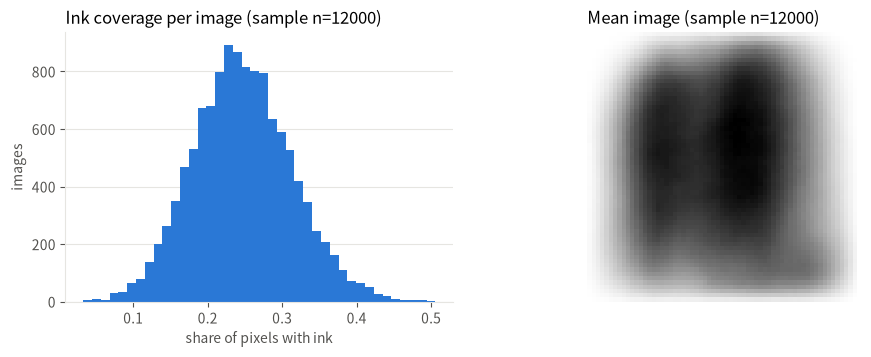

In [20]:
figure, (left_axis, right_axis) = plt.subplots(1, 2, figsize=(11, 3.5))
left_axis.hist(ink_share_per_image, bins=40, color=SERIES_BLUE)
left_axis.set_xlabel("share of pixels with ink")
left_axis.set_ylabel("images")
left_axis.set_title(f"Ink coverage per image (sample n={len(ink_share_per_image)})", loc="left")

right_axis.imshow(sample_images.mean(axis=0), cmap="gray_r")
right_axis.set_title(f"Mean image (sample n={len(sample_images)})", loc="left")
right_axis.axis("off")
plt.show()

In [21]:
ink_rows = sample_images.any(axis=2)
ink_columns = sample_images.any(axis=1)
box_heights = ink_rows.sum(axis=1)
box_widths = ink_columns.sum(axis=1)
pd.DataFrame({"ink box height (of 63)": box_heights, "ink box width (of 64)": box_widths}).describe().round(1)

,ink box height (of 63),ink box width (of 64)
count,12000.0,12000.0
mean,59.7,51.8
std,5.3,8.3
min,10.0,16.0
25%,58.0,46.0
50%,63.0,53.0
75%,63.0,59.0
max,63.0,63.0


In [22]:
ink_share_by_class = pd.Series(ink_share_per_image).groupby(image_sample_rows["character_class"]).agg(["count", "mean", "median"]).round(4)
ink_share_by_class

,count,mean,median
character_class,,,
CJK ideograph,11721,0.2495,0.2463
kana,279,0.1346,0.1290


## 6. Overlap with KanjiVG

In [23]:
kanjivg_characters = {chr(int(p.stem, 16)) for p in KANJIVG_DIR.glob("*.svg")}
etl9_characters = set(samples["char"])
print("ETL9B characters:", len(etl9_characters), " KanjiVG characters:", len(kanjivg_characters))

ETL9B characters: 3036  KanjiVG characters: 6703


In [24]:
common_kanji = set(etl9_characters) & set(kanjivg_characters)

print("Common characters:", len(common_kanji))

Common characters: 3036


In [25]:
etl9_only = etl9_characters - kanjivg_characters
kanjivg_only = kanjivg_characters - etl9_characters
overlap_table = pd.DataFrame({
    "characters": [len(common_kanji), len(etl9_only), len(kanjivg_only)],
}, index=["in both", "ETL9B only", "KanjiVG only"])
overlap_table

,characters
in both,3036
ETL9B only,0
KanjiVG only,3667


In [26]:
overlap_by_class = pd.DataFrame({
    "ETL9B classes": pd.Series([character_class(c) for c in etl9_characters]).value_counts(),
    "also in KanjiVG": pd.Series([character_class(c) for c in common_kanji]).value_counts(),
}).fillna(0).astype(int)
overlap_by_class["share covered"] = (overlap_by_class["also in KanjiVG"] / overlap_by_class["ETL9B classes"]).round(3)
overlap_by_class

,ETL9B classes,also in KanjiVG,share covered
CJK ideograph,2965,2965,1.0
kana,71,71,1.0


In [27]:
print("ETL9B characters missing from KanjiVG:", len(etl9_only))
print("".join(sorted(etl9_only)))

ETL9B characters missing from KanjiVG: 0



In [28]:
kanjivg_only_by_class = pd.Series([character_class(c) for c in kanjivg_only]).value_counts()
kanjivg_only_by_class.rename("KanjiVG characters without ETL9B samples")

CJK ideograph    3481
kana              110
other              76
Name: KanjiVG characters without ETL9B samples, dtype: int64

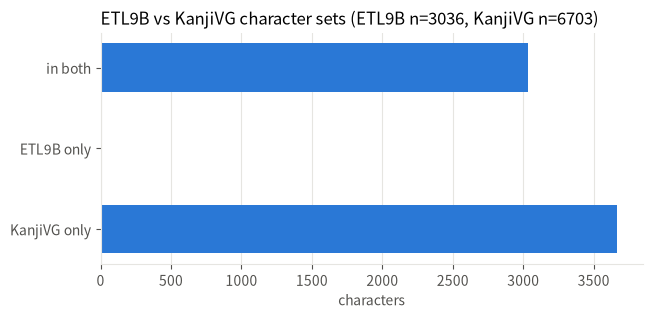

In [29]:
figure, axis = plt.subplots(figsize=(7, 3))
axis.barh(overlap_table.index[::-1], overlap_table["characters"][::-1], color=SERIES_BLUE, height=0.6)
axis.set_xlabel("characters")
axis.set_title(f"ETL9B vs KanjiVG character sets (ETL9B n={len(etl9_characters)}, KanjiVG n={len(kanjivg_characters)})",
               loc="left")
axis.grid(True, axis="x")
axis.grid(False, axis="y")
plt.show()

In [30]:
common_samples = samples["char"].isin(common_kanji).sum()
print("ETL9B samples whose class is in KanjiVG:", common_samples, "of", len(samples))

ETL9B samples whose class is in KanjiVG: 607200 of 607200
